# Lezione 10 — Notebook Docente
## Caso Aula: China Evergrande 2021

Soluzione di riferimento coerente con la Scheda Caso Aula.

- $N_{\mathrm{MC}}=50\,000$;
- seed $2027$;
- $T=4$ trimestri;
- misura fisica;
- una traiettoria sistemica comune per replica;
- *Common Random Numbers* nel confronto tra portafogli.

## 1. Import e CVaR empirico

Il CVaR è implementato mediante
$$
\operatorname{CVaR}_{\alpha}(L)=\frac{1}{1-\alpha}\int_{\alpha}^1 q_u(L)\,du,
$$
coerentemente con la definizione quantile-based del Capitolo 9.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

def empirical_var(x, alpha):
    xs=np.sort(np.asarray(x,float)); n=len(xs)
    return xs[max(0, math.ceil(alpha*n)-1)]

def empirical_cvar(x, alpha):
    xs=np.sort(np.asarray(x,float)); n=len(xs); a=alpha*n; k=int(np.floor(a))
    if np.isclose(a,k):
        integ=xs[k:].sum()/n
    else:
        integ=((k+1)/n-alpha)*xs[k] + xs[k+1:].sum()/n
    return integ/(1-alpha)

def risk_summary(x):
    x=np.asarray(x,float)
    return {
      "Perdita media":x.mean(),
      "Varianza":x.var(ddof=0),
      "Deviazione standard":x.std(ddof=0),
      "VaR 95%":empirical_var(x,.95),
      "CVaR 95%":empirical_cvar(x,.95),
      "VaR 99%":empirical_var(x,.99),
      "CVaR 99%":empirical_cvar(x,.99)}

## 2. Parametri e controlli preliminari

In [2]:
N_MC=50_000; SEED=2027; T=4
sys_states=np.array(["N","S","C"]); cred_states=np.array(["BBB","BB","B","CCC","D"])
si={s:i for i,s in enumerate(sys_states)}; ci={s:i for i,s in enumerate(cred_states)}

Q=np.array([[.84,.15,.01],[.20,.62,.18],[.08,.30,.62]])
P={
"N":np.array([[.955,.038,.005,.001,.001],[.025,.925,.038,.009,.003],[.005,.035,.885,.060,.015],[.001,.004,.025,.900,.070],[0,0,0,0,1.]]),
"S":np.array([[.925,.060,.011,.003,.001],[.012,.875,.085,.022,.006],[.003,.020,.810,.135,.032],[0,.003,.022,.855,.120],[0,0,0,0,1.]]),
"C":np.array([[.830,.115,.035,.015,.005],[.004,.745,.145,.075,.031],[0,.008,.650,.242,.100],[0,0,.008,.692,.300],[0,0,0,0,1.]])}
LGD=np.array([.55,.70,.85])
phi=np.array([[0,.04,.11,.26],[-.03,0,.07,.19],[-.07,-.04,0,.13],[-.12,-.08,-.04,0]])
assert np.allclose(Q.sum(1),1)
for A in P.values():
    assert np.allclose(A.sum(1),1) and np.allclose(A[-1],[0,0,0,0,1])
print("Matrici: OK")

Matrici: OK


## 3. Portafogli

In [3]:
ratings_lbl=["B"]+["BBB"]*10+["BB"]*10+["B"]*10+["CCC"]*5
r0=np.array([ci[x] for x in ratings_lbl])
V0=np.array([30.]+[6.]*10+[5.]*10+[4.]*10+[4.]*5)
V1=V0.copy(); V1[0]=20
bbb=np.arange(1,11); bb=np.arange(11,21)
V1[bbb]+=10*V0[bbb]/110; V1[bb]+=10*V0[bb]/110
assert len(V0)==36 and np.isclose(V0.sum(),200) and np.isclose(V1.sum(),200)
assert np.isclose(V1[0],20) and np.isclose((V1-V0).sum(),0)
pd.DataFrame({"Rating":ratings_lbl,"V_base":V0,"V_lim":V1}).head(15)

,Rating,V_base,V_lim
0,B,30.0000,20.0000
1,BBB,6.0000,6.5455
2,BBB,6.0000,6.5455
3,BBB,6.0000,6.5455
4,BBB,6.0000,6.5455
5,BBB,6.0000,6.5455
6,BBB,6.0000,6.5455
7,BBB,6.0000,6.5455
8,BBB,6.0000,6.5455
9,BBB,6.0000,6.5455


## 4. Simulazione delle traiettorie

In [4]:
rng=np.random.default_rng(SEED); n=len(r0)
M=np.empty((N_MC,T),np.int8); X=np.empty((N_MC,T+1,n),np.int8)
tau=np.full((N_MC,n),T+1,np.int8); dreg=np.full((N_MC,n),-1,np.int8)
M[:,0]=si["S"]; X[:,0,:]=r0

def draw_rows(prob,u):
    return (u[:,None] > np.cumsum(prob,axis=1)).sum(1)

for t in range(T):
    cur=X[:,t,:]; nxt=cur.copy()
    for lab,mcode in si.items():
        rows=np.where(M[:,t]==mcode)[0]
        if not len(rows): continue
        A=P[lab]
        for j in range(n):
            st=cur[rows,j]; dr=draw_rows(A[st],rng.random(len(rows))); nxt[rows,j]=dr
            fd=(st!=ci["D"]) & (dr==ci["D"])
            if fd.any():
                rr=rows[fd]; tau[rr,j]=t+1; dreg[rr,j]=mcode
    X[:,t+1,:]=nxt
    if t<T-1: M[:,t+1]=draw_rows(Q[M[:,t]],rng.random(N_MC))
D=ci["D"]
for t in range(T):
    m=X[:,t,:]==D
    assert np.all(X[:,t+1,:][m]==D)
print("Traiettorie simulate:",X.shape)

Traiettorie simulate: (50000, 5, 36)


## 5. Perdite individuali e di portafoglio

In [5]:
fin=X[:,-1,:]; default=tau<=T; lr=np.zeros((N_MC,n))
for j in range(n):
    nd=~default[:,j]
    lr[nd,j]=phi[r0[j],fin[nd,j]]
    dd=default[:,j]
    lr[dd,j]=LGD[dreg[dd,j]]
Li0=lr*V0; Li1=lr*V1
L0=Li0.sum(1); L1=Li1.sum(1); dL=L1-L0
for j in range(n):
    for tt in range(1,T+1):
        m=tau[:,j]==tt
        if m.any():
            assert np.all(X[m,tt-1,j]!=D) and np.all(X[m,tt,j]==D)
            assert np.all(dreg[m,j]==M[m,tt-1])
print("Perdite e default: OK")

Perdite e default: OK


## 6. Misure di rischio e analisi del regime sistemico

In [6]:
R0=risk_summary(L0); R1=risk_summary(L1)
tab=pd.DataFrame({"Base":R0,"Limite":R1}); tab["Differenza"]=tab["Limite"]-tab["Base"]
crisis=np.any(M==si["C"],axis=1); ndef=default.sum(1)
display(tab)
display(pd.DataFrame({
"Quantità":["P(ingresso in C)","Numero medio default","E[L|C]","E[L|no C]","E[Delta L]","P(Delta L>0)"],
"Valore":[crisis.mean(),ndef.mean(),L0[crisis].mean(),L0[~crisis].mean(),dL.mean(),(dL>0).mean()]}))

,Base,Limite,Differenza
Perdita media,26.1094,24.8156,-1.2939
Varianza,274.6820,224.1935,-50.4885
Deviazione standard,16.5735,14.9731,-1.6004
VaR 95%,60.3100,55.0655,-5.2445
CVaR 95%,68.9243,63.0214,-5.9029
VaR 99%,74.4000,68.2255,-6.1745
CVaR 99%,79.7036,73.5922,-6.1114


,Quantità,Valore
0,P(ingresso in C),0.3677
1,Numero medio default,5.3294
2,E[L|C],40.9753
3,E[L|no C],17.4645
4,E[Delta L],-1.2939
5,P(Delta L>0),0.5299


## 7. Tabelle di portafoglio

In [7]:
display(pd.DataFrame({
"Gruppo":["Evergrande","BBB","BB","Altri B","CCC"],
"N":[1,10,10,10,5],
"Rating":["B","BBB","BB","B","CCC"],
"V per debitore":[30,6,5,4,4],
"V complessivo":[30,60,50,40,20]}))
display(pd.DataFrame({
"Gruppo":["Evergrande","BBB","BB","Altri B","CCC"],
"N":[1,10,10,10,5],
"Rating":["B","BBB","BB","B","CCC"],
"V per debitore":[20,V1[bbb][0],V1[bb][0],4,4],
"V complessivo":[20,V1[bbb].sum(),V1[bb].sum(),40,20]}))

,Gruppo,N,Rating,V per debitore,V complessivo
0,Evergrande,1,B,30,30
1,BBB,10,BBB,6,60
2,BB,10,BB,5,50
3,Altri B,10,B,4,40
4,CCC,5,CCC,4,20


,Gruppo,N,Rating,V per debitore,V complessivo
0,Evergrande,1,B,20.0000,20.0000
1,BBB,10,BBB,6.5455,65.4545
2,BB,10,BB,5.4545,54.5455
3,Altri B,10,B,4.0000,40.0000
4,CCC,5,CCC,4.0000,20.0000


## 8. Grafici richiesti

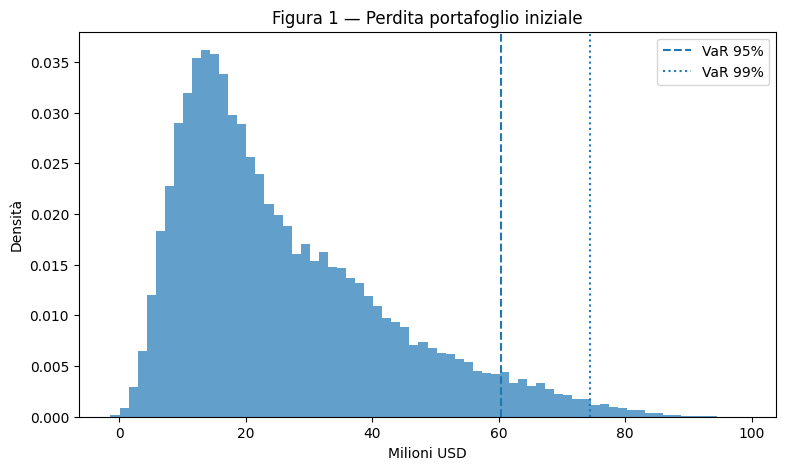

In [8]:
fig,ax=plt.subplots(figsize=(9,5))
ax.hist(L0,bins=70,density=True,alpha=.7)
ax.axvline(R0["VaR 95%"],ls="--",label="VaR 95%"); ax.axvline(R0["VaR 99%"],ls=":",label="VaR 99%")
ax.set(title="Figura 1 — Perdita portafoglio iniziale",xlabel="Milioni USD",ylabel="Densità"); ax.legend(); plt.show()

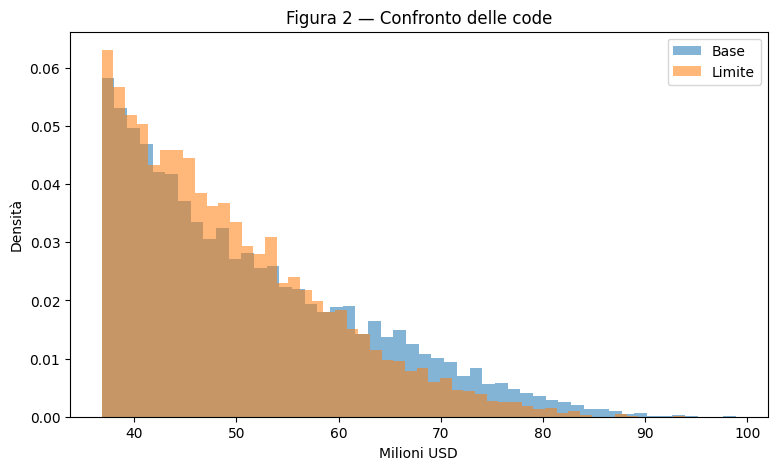

In [9]:
q80=min(np.quantile(L0,.80),np.quantile(L1,.80))
fig,ax=plt.subplots(figsize=(9,5))
ax.hist(L0[L0>=q80],bins=50,density=True,alpha=.55,label="Base")
ax.hist(L1[L1>=q80],bins=50,density=True,alpha=.55,label="Limite")
ax.set(title="Figura 2 — Confronto delle code",xlabel="Milioni USD",ylabel="Densità"); ax.legend(); plt.show()

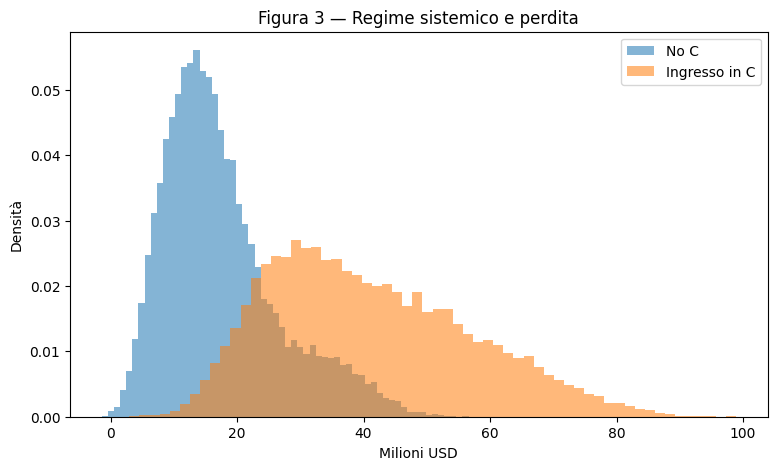

In [10]:
fig,ax=plt.subplots(figsize=(9,5))
ax.hist(L0[~crisis],bins=60,density=True,alpha=.55,label="No C")
ax.hist(L0[crisis],bins=60,density=True,alpha=.55,label="Ingresso in C")
ax.set(title="Figura 3 — Regime sistemico e perdita",xlabel="Milioni USD",ylabel="Densità"); ax.legend(); plt.show()

## 9. Stabilità Monte Carlo

In [11]:
display(pd.DataFrame({
"Base 50k":risk_summary(L0),"Base 25k":risk_summary(L0[:25000]),
"Limite 50k":risk_summary(L1),"Limite 25k":risk_summary(L1[:25000])}))

,Base 50k,Base 25k,Limite 50k,Limite 25k
Perdita media,26.1094,26.0820,24.8156,24.8081
Varianza,274.6820,273.8140,224.1935,223.7324
Deviazione standard,16.5735,16.5473,14.9731,14.9577
VaR 95%,60.3100,60.2300,55.0655,54.9709
CVaR 95%,68.9243,68.8852,63.0214,63.0324
VaR 99%,74.4000,74.3000,68.2255,68.2073
CVaR 99%,79.7036,80.1058,73.5922,74.0636


## 10. Chiusura docente

Controlli coperti: matrici stocastiche, default assorbente, \(M_0=S\), primo default, LGD del regime che governa la transizione, esclusività migration-loss/default-loss, investimenti, riallocazione, riconciliazione, seed, VaR/CVaR, stabilità.

Proprietà **PER COSTRUZIONE**: una traiettoria sistemica per replica, estrazioni individuali condizionate al regime, riuso delle stesse traiettorie nei due portafogli.

Interpretazione: la policy di concentrazione agisce soprattutto sulle misure di coda, ma non genera dominanza replica per replica.